In [ ]:
import os
import glob
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

In [ ]:

shp_input_dir = "../data/new_blocks/"
json_output_dir = "../data/raw/new_geojson_blocks"

# Create the output folder if it doesn't exist
os.makedirs(json_output_dir, exist_ok=True)

# 2. Find all the .shp files
shapefiles = glob.glob(os.path.join(shp_input_dir, "*.shp"))

print(f"Found {len(shapefiles)} Shapefiles. Starting conversion...\n")

for shp_path in shapefiles:
    # Get the file name without the extension (e.g., 'Chaos_A')
    basename = os.path.splitext(os.path.basename(shp_path))[0]
    
    # Define where the new JSON will be saved
    out_path = os.path.join(json_output_dir, f"{basename}.json")
    
    # 3. Read and Convert
    print(f"Converting {basename}...")
    try:
        # Load the shapefile
        gdf = gpd.read_file(shp_path)
        
        # Save it as a GeoJSON
        gdf.to_file(out_path, driver="GeoJSON")
    except Exception as e:
        print(f"[ERROR] Failed to convert {basename}: {e}")

print("\nAll Shapefiles successfully converted to GeoJSON!")

Found 3 Shapefiles. Starting conversion...

Converting Chaos_bb_new...
Converting Chaos_aa_new...
Converting Chaos_C_new...

All Shapefiles successfully converted to GeoJSON!


Fusing Annotations for Uncertainty Mapping...



/Users/jjwill18/miniforge3/envs/chaos_ml_env/lib/python3.11/site-packages/pyogrio/raw.py:200: RuntimeWarning: Several features with id = 40 have been found. Altering it to be unique. This warning will not be emitted anymore for this layer
  return ogr_read(


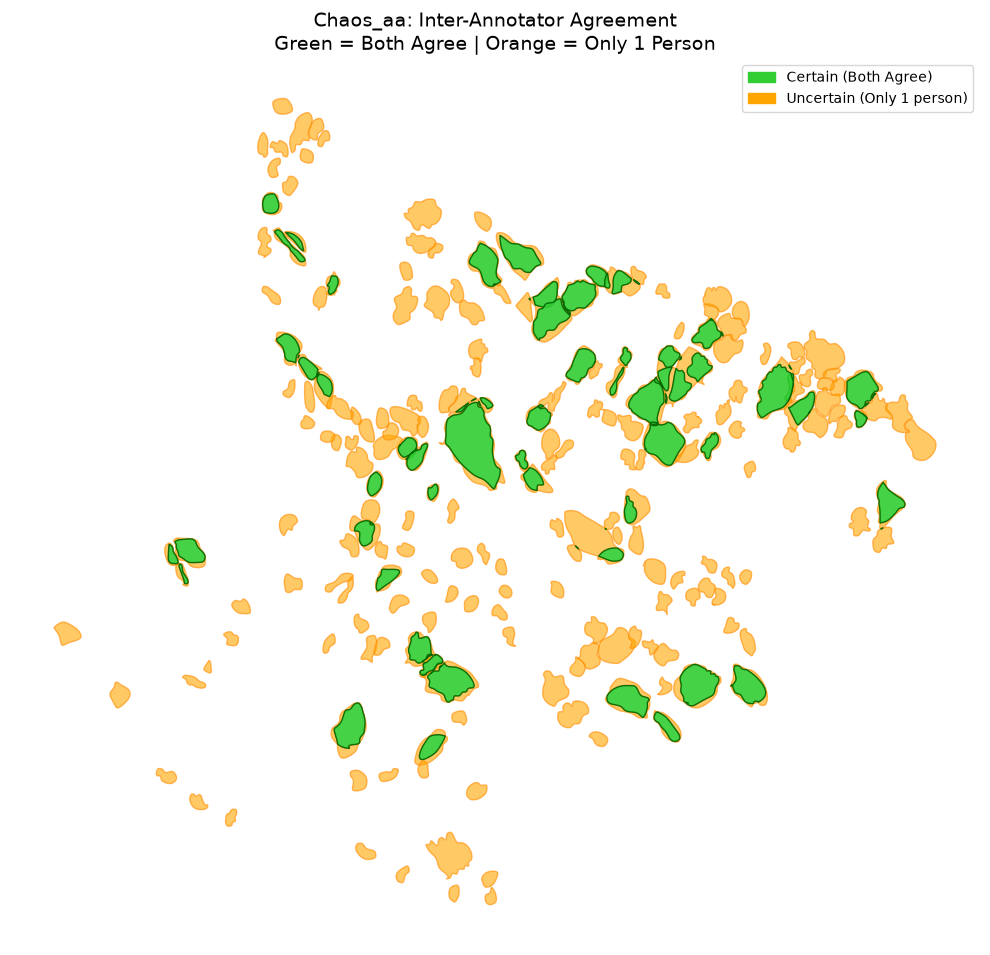

/Users/jjwill18/miniforge3/envs/chaos_ml_env/lib/python3.11/site-packages/pyogrio/raw.py:200: RuntimeWarning: Several features with id = 68 have been found. Altering it to be unique. This warning will not be emitted anymore for this layer
  return ogr_read(


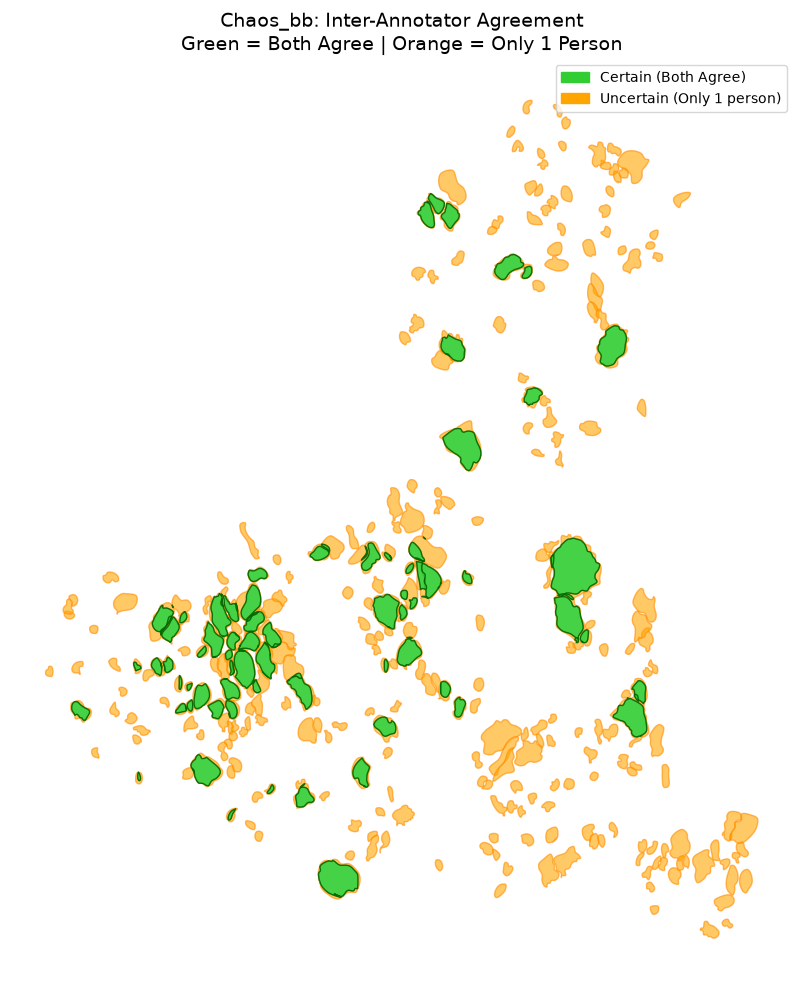

/Users/jjwill18/miniforge3/envs/chaos_ml_env/lib/python3.11/site-packages/pyogrio/raw.py:200: RuntimeWarning: Several features with id = 35 have been found. Altering it to be unique. This warning will not be emitted anymore for this layer
  return ogr_read(


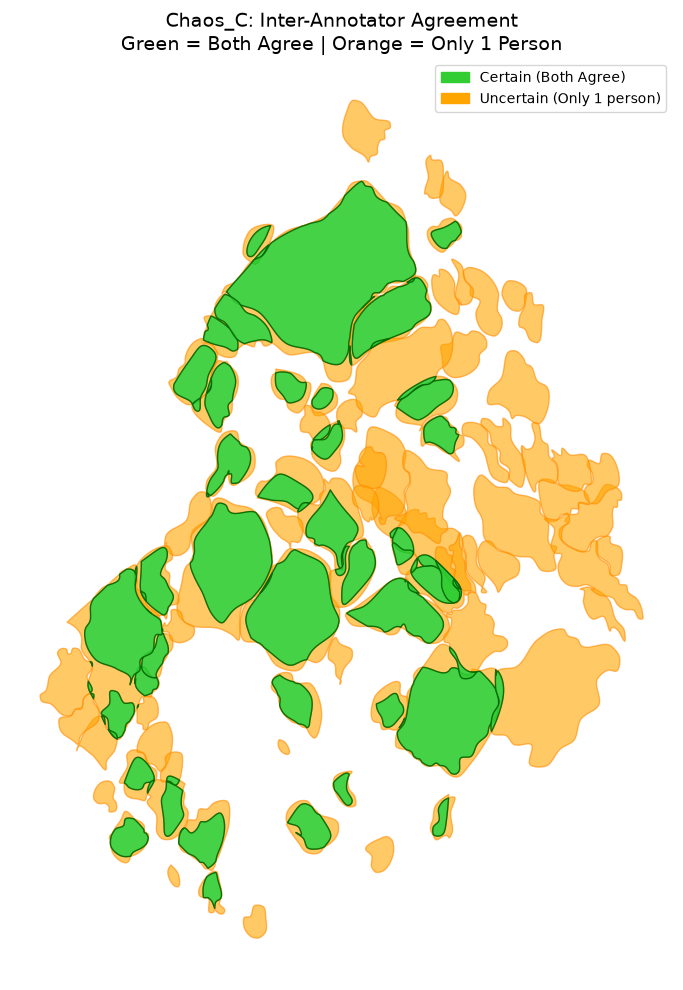

Finished testing!


In [6]:
import os
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

# 1. Define your paths (Update these!)
old_dir = "../data/raw/geojson_blocks"
new_dir = "../data/raw/new_geojson_blocks"
out_dir = "../data/new/combined/"
os.makedirs(out_dir, exist_ok=True)

# 2. Pick your 3 test regions
regions_to_test = ["Chaos_aa", "Chaos_bb", "Chaos_C"]

print("Fusing Annotations for Uncertainty Mapping...\n")

for region in regions_to_test:
    old_path = os.path.join(old_dir, f"{region}.json")
    new_path = os.path.join(new_dir, f"{region}.json")
    
    # Skip if one of them didn't label this region
    if not os.path.exists(old_path) or not os.path.exists(new_path):
        print(f"[SKIP] Missing files for {region}")
        continue
        
    old_gdf = gpd.read_file(old_path)
    new_gdf = gpd.read_file(new_path)
    
    # Ensure they are in the same CRS
    if old_gdf.crs != new_gdf.crs:
        new_gdf = new_gdf.to_crs(old_gdf.crs)

    # ==========================================
    # 3. THE GIS MATH
    # ==========================================
    # CLASS 0 (CERTAIN): Where they 100% overlap
    certain_blocks = gpd.overlay(old_gdf, new_gdf, how='intersection')
    certain_blocks['class_id'] = 0
    certain_blocks['confidence'] = "High"

    # CLASS 1 (UNCERTAIN): Where they disagree (Symmetric Difference)
    uncertain_blocks = gpd.overlay(old_gdf, new_gdf, how='symmetric_difference')
    uncertain_blocks['class_id'] = 1
    uncertain_blocks['confidence'] = "Low"

    # Combine them into one master file for this region
    master_gdf = gpd.GeoDataFrame(pd.concat([certain_blocks, uncertain_blocks], ignore_index=True))
    
    # Save it (Optional)
    # master_gdf.to_file(os.path.join(out_dir, f"{region}_master.json"), driver="GeoJSON")
    
    # ==========================================
    # 4. VISUALIZE THE UNCERTAINTY
    # ==========================================
    fig, ax = plt.subplots(1, 1, figsize=(10, 10))
    
    # Plot Uncertain areas in Orange
    if not uncertain_blocks.empty:
        uncertain_blocks.plot(ax=ax, facecolor="orange", edgecolor="darkorange", alpha=0.6, label="Uncertain (Disagreement)")
        
    # Plot Certain areas in Green on top
    if not certain_blocks.empty:
        certain_blocks.plot(ax=ax, facecolor="limegreen", edgecolor="darkgreen", alpha=0.9, label="Certain (100% Agreement)")

    ax.set_title(f"{region}: Inter-Annotator Agreement\nGreen = Both Agree | Orange = Only 1 Person", fontsize=14)
    ax.axis('off')
    
    # Create custom legend
    import matplotlib.patches as mpatches
    legend_handles = [
        mpatches.Patch(color='limegreen', label='Certain (Both Agree)'),
        mpatches.Patch(color='orange', label='Uncertain (Only 1 person)')
    ]
    ax.legend(handles=legend_handles, loc='upper right')
    
    plt.tight_layout()
    plt.show()

print("Finished testing!")